In [276]:
# 그래프관련 import 
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 프로그램 
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier # 분류 클래스
from sklearn.neighbors import KNeighborsRegressor # 예측 클래스
from sklearn.linear_model import LinearRegression # 예측 클래스
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위 클래스
from sklearn.preprocessing import StandardScaler  # 정규화 클래스
from sklearn.model_selection import train_test_split

In [277]:
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
     21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
     22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
     27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
     36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
     40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
     )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
     110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
     130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
     197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
     514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
     820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
     1000.0, 1000.0]
     )

In [278]:
# 1차원 배열들을 마치 세로 열(Column)처럼 옆으로 하나씩 붙여서 2차원 배열로 만들어주는 함수
data = np.column_stack((perch_length,perch_weight))
data[:2]

array([[ 8.4,  5.9],
       [13.7, 32. ]])

In [279]:
train_data, test_data, train_label, test_label = train_test_split(perch_length,perch_weight)
test_data

array([24. , 21. , 19. , 27.5, 39. , 18.7, 37. , 43.5, 17.4, 25. , 27.5,
       26.5, 43. , 21. ])

In [280]:
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)
train_data
test_data

array([[24. ],
       [21. ],
       [19. ],
       [27.5],
       [39. ],
       [18.7],
       [37. ],
       [43.5],
       [17.4],
       [25. ],
       [27.5],
       [26.5],
       [43. ],
       [21. ]])

In [281]:
train_poly = np.column_stack((train_data**2,train_data))
train_poly[:2]
test_poly = np.column_stack((test_data**2,test_data))
test_poly[:2]

array([[576.,  24.],
       [441.,  21.]])

In [282]:
lr = LinearRegression()
lr.fit(train_poly,train_label)

predict = lr.predict(train_poly)
print('예측 무게 : ', predict)

score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print('train 정확도 :', score)
print('test 정확도 :', score2)


예측 무게 :  [  81.21951674  691.83127916   17.22231665  895.57624815  333.17818294
  114.67150034  719.31402869 1091.322563     22.0717782   834.65727551
  282.74650298  197.46812458   13.6585025   612.63037981  142.05159035
  289.69124075  180.66062432  834.65727551  895.57624815 1023.9088919
  130.2643621   383.80699864  587.31252977  895.57624815   55.45063152
  130.2643621   895.57624815  130.2643621    33.08522809 1160.90113359
  167.24972146  142.05159035  227.21254461  108.31358023  130.2643621
   88.52769784  146.91802461  130.2643621   307.43194259  505.28020168
  664.8897545   154.38004347]
train 정확도 : 0.9749459733698382
test 정확도 : 0.9547999475003097


In [283]:
print(lr.coef_,lr.intercept_)

[  1.08244974 -24.5945571 ] 147.4389423571603


In [284]:
print(lr.coef_[0])

1.0824497435368754


In [285]:
point = np.arange(15,50)
print(point)

[15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38
 39 40 41 42 43 44 45 46 47 48 49]


In [286]:
# 25 입력받아 산점도 그래프에 표시하고 곡선도 출력하시오 
# in_data = 25
# result = lr.predict([[in_data**2,in_data]])
# print("예측 무게 : ", result)

in_data = 1000
result = lr.predict([[in_data**2,in_data]])
print("예측 무게 : ", result)

예측 무게 :  [1058002.62538264]


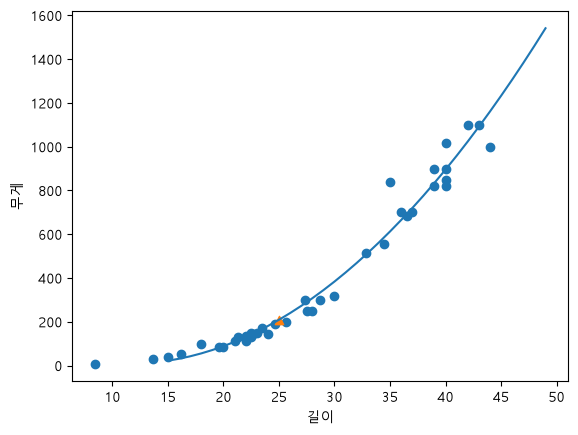

In [287]:
plt.scatter(train_data,train_label)
plt.scatter(25,208.14, marker='^')
plt.plot(point,lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_)
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

In [288]:
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]

# 빙어 - 14 
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [289]:
total_length = bream_length + smelt_length
total_weight = bream_weight + smelt_weight  

In [290]:
label = [1]*35 + [0]*14
# label = ['도미']*35 + ['빙어']*14

data = np.column_stack((total_length, total_weight))

In [291]:
train_data, test_data, train_label, test_label = train_test_split(data, label)

In [292]:
lr = LinearRegression()
lr.fit(train_data,train_label)

predict = lr.predict(test_data)
print('무게 예측 :', predict)

score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print('무게 예측 :', score)
print('무게 예측 :', score)

무게 예측 : [0.98909722 0.06459542 1.20079917 0.80566245 0.27283646 0.0063425
 0.93040473 1.0389715  1.08626951 0.07673313 0.85802815 0.96304776
 1.0620395 ]
무게 예측 : 0.9467995595799388
무게 예측 : 0.9467995595799388


In [293]:
print(lr.coef_,lr.intercept_)

[ 0.07281615 -0.00101063] -0.7992941441445888


In [294]:
print(lr.coef_[0])

0.07281614898197528


In [295]:
point = np.arange(15,50)
print(point)

[15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38
 39 40 41 42 43 44 45 46 47 48 49]


In [296]:
in_data = 25
result = lr.predict([[in_data**2,in_data]])
print("예측 무게 : ", result)

예측 무게 :  [44.6855331]


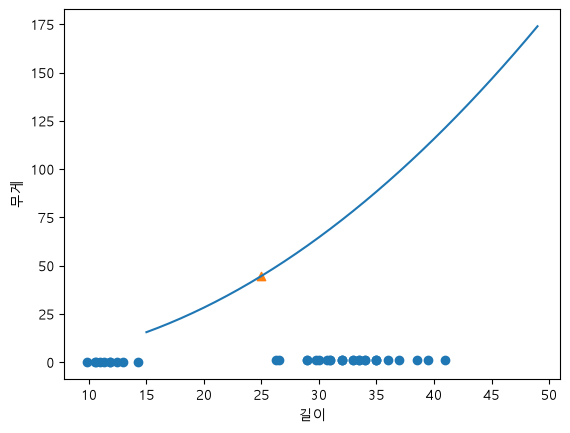

In [300]:
plt.scatter(train_data[:, 0], train_label)
plt.scatter(25, 44.685, marker='^')
plt.plot(point, lr.coef_[0]*point**2 + lr.coef_[1]*point + lr.intercept_)
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()